# vibrational.retrieval

Actual saved frozen-model results, rechecked and visualized by executed cells. The cells below do not rerun the model. Source files and hashes identify the original inference. No hypothetical predictions are used.

In [1]:
import json, sys, io
from pathlib import Path
from IPython.display import display, Markdown, SVG
root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'openmolspec_bench').is_dir()), None)
if root is None:
    raise RuntimeError('Run from the cloned release repository; see Quick Start')
sys.path.insert(0, str(root / 'scripts'))
from documentation_evidence import load_evidence, compact, recompute, render
from documentation_content import results_table
evidence = load_evidence('vibrational.retrieval')
print(json.dumps({'task': evidence['task'], 'status': evidence['status'], 'source_sha256': evidence['source_hashes']}, indent=2, ensure_ascii=False))

{
  "task": "vibrational.retrieval",
  "status": "recorded_results",
  "source_sha256": {
    "vibrational_ranked_examples_20261117.json": "b7e464aa11e85fdcae7245d987d92f272d6c1a5e47d697734df17d26731744e3"
  }
}


## Actual input and output

First recorded example; arrays over eight entries show length and a preview. Full values are in the downloadable evidence JSON.

In [2]:
example = evidence['examples'][0]
print(json.dumps(compact(example), indent=2, ensure_ascii=False))

{
  "sample_id": "ZINCV2-ZINC000646741030",
  "input": {
    "ir": {
      "length": 1024,
      "first_values": [
        0.15220004320144653,
        0.190755695104599,
        0.2037702202796936,
        0.1804114133119583,
        0.1386023461818695,
        0.10100352019071579,
        0.07402963191270828,
        0.05563068017363548
      ]
    },
    "raman": {
      "length": 1024,
      "first_values": [
        0.04284051060676575,
        0.0596662312746048,
        0.059223152697086334,
        0.04435715824365616,
        0.03070877492427826,
        0.02493642456829548,
        0.021241741254925728,
        0.01620982028543949
      ]
    },
    "nmr_h_shifts_ppm": [],
    "nmr_c_shifts_ppm": []
  },
  "reference_smiles": "O=C(c1n[nH]c2ccccc12)N1CCOC2CC21",
  "ranked_candidates": {
    "length": 10,
    "first_values": [
      {
        "smiles": "O=C1CNc2nonc2N1",
        "score": 0.47853392362594604,
        "reference_match": false
      },
      {
        "smiles": "C

## Recorded run table and recomputed diagnostics

In [3]:
display(Markdown(results_table(evidence, True)))
print(json.dumps(recompute(evidence), indent=2, ensure_ascii=False))

| Dataset / scope | Model / variant | Metric | Value |
| --- | --- | --- | ---: |
| recorded sample | recorded model | recall_at_1 | 0.0625 |
| recorded sample | recorded model | mrr | 0.257068 |
| recorded sample | recorded model | queries | 16 |
| recorded sample | recorded model | candidate_pool | 16 |


{
  "scope": "Saved model outputs are shown directly; aggregate metrics are in the run table.",
  "recorded_runs": 1,
  "real_examples": 3
}


## Prediction / reference figure

Missing-channel ablation of a four-modal checkpoint. Poor scores do not validate a stand-alone IR/Raman model; use compatible unimodal weights or plan separate adaptation.

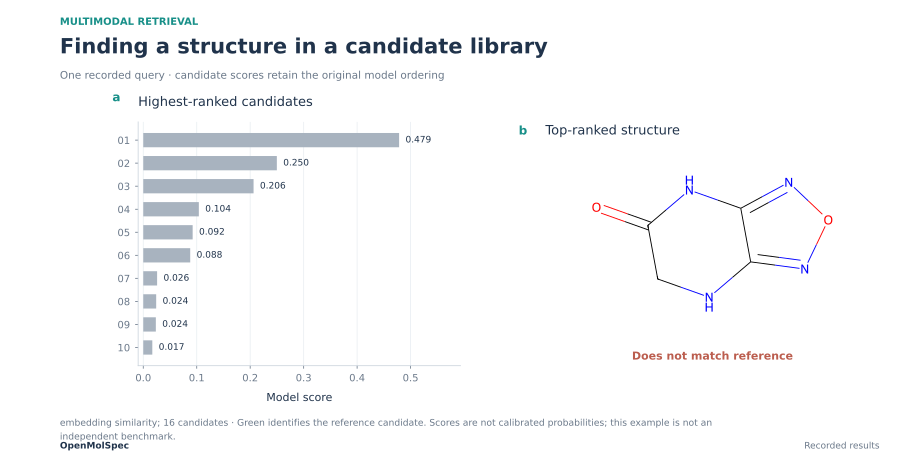

In [4]:
figure = render('vibrational.retrieval', evidence)
image = io.StringIO()
figure.savefig(image, format='svg', metadata={'Date': None})
display(SVG(image.getvalue()))
import matplotlib.pyplot as plt
plt.close(figure)

## Rerun the model

Use the task page and Quick Start to configure the original model runtime, checkpoint and dataset. The analysis environment alone is sufficient for all cells above.

[Task](../tasks/vibrational-retrieval.md) · [Quick Start](../quickstart.md)
